# Bedah Kasus 2: Dataset Profil Mahasiswa
### Pembuatan Data Sintetis, Analisis Deskriptif, dan Visualisasi Berdasarkan Tipe Data

| | |
|---|---|
| **Nama** | **Ganesia Alkhan Fikriano** |
| **NIM** | **241051019** |

---
**Daftar isi**
1. Pemahaman kasus & tipe data
2. Persiapan lingkungan
3. Pembuatan data sintetis (1.000 baris)
4. Validasi struktur & kualitas data
5. Analisis **Jurusan** (kategorik nominal)
6. Analisis **Semester** (kategorik ordinal)
7. Analisis **IPK** (numerik kontinu)
8. Analisis **Usia** (numerik kontinu)
9. Hubungan antar variabel
10. Temuan utama & kesimpulan
11. Menjalankan dashboard Streamlit

## 1. Pemahaman Kasus & Tipe Data

Gambar tugas menunjukkan dataset profil mahasiswa dengan **4 kolom** dan 2 baris contoh, masing-masing sudah dipetakan ke skala pengukuran:

| Kolom | Contoh | Tipe / Skala | Penjelasan | Visualisasi yang sesuai | Statistik yang bermakna |
|---|---|---|---|---|---|
| **Jurusan** | Sistem Informasi, Manajemen | Kategorik - **Nominal** | Hanya label pembeda, tanpa urutan | Bar chart / Pie chart | Frekuensi, proporsi, modus |
| **Semester** | 3, 1 | Kategorik - **Ordinal** | Ada tingkatan dan urutan jelas (1 -> 2 -> 3), tetapi jarak antar tingkat tidak harus sama | Bar chart **berurutan** | Frekuensi, modus, **median**, kuartil |
| **IPK** | 3,85; 3,50 | Numerik - **Kontinu** | Berupa rentang/desimal (0,00-4,00) | Histogram atau Box plot | Mean, median, simpangan baku, skewness |
| **Usia** | 20, 19 | Numerik - **Kontinu** | Pengukuran waktu hidup yang secara konsep kontinu | Histogram atau Box plot | Mean, median, simpangan baku, skewness |

**Catatan penting**
- Pada **ordinal**, urutan kategori harus dipertahankan (1, 2, 3, ..., bukan diurutkan berdasarkan frekuensi), dan ukuran pemusatan yang paling tepat adalah median/modus.
- **Usia** pada gambar diberi label kontinu, tetapi pada praktiknya dicatat dalam *tahun penuh* (20, 19), sehingga nilainya tampak bulat. Karena itu histogram Usia memakai lebar kelas 1 tahun.
- **Konvensi warna** mengikuti gambar: **biru** = kategorik (nominal dan ordinal), **oranye** = numerik.

## 2. Persiapan Lingkungan

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display, Markdown

# ----- Identitas (wajib) -----
NAMA, NIM = "Ganesia Alkhan Fikriano", "241051019"

# ----- Warna sesuai gambar tugas -----
BIRU, BIRU_TUA, ORANYE = "#2E9BD6", "#1F6FA8", "#F5A03A"
PALET_JUR = sns.color_palette("tab10", 8)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 11.5,
                     "axes.labelsize": 10, "figure.facecolor": "#F6F5F1", "savefig.facecolor": "#F6F5F1"})
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

SEM_URUT = list(range(1, 11))                    # urutan ordinal Semester
PREDIKAT = ["Perlu Pembinaan", "Memuaskan", "Sangat Memuaskan", "Dengan Pujian"]


def selesai(fig, judul=None):
    """Tampilkan figure dengan judul dan identitas mahasiswa di setiap grafik."""
    if judul:
        fig.suptitle(judul, fontsize=14, fontweight="bold")
    fig.text(0.995, 0.006, f"{NAMA} | NIM {NIM}", ha="right", va="bottom", fontsize=8, color="#666666")
    fig.tight_layout(rect=[0, 0.03, 1, 0.95 if judul else 1])
    plt.show()


display(Markdown(f"**Pemilik notebook:** {NAMA} &nbsp;|&nbsp; **NIM:** {NIM}"))

**Pemilik notebook:** Ganesia Alkhan Fikriano &nbsp;|&nbsp; **NIM:** 241051019

## 3. Pembuatan Data Sintetis (1.000 baris)

Agar data **realistis**, generator memakai aturan berikut:

- **8 jurusan** dengan proporsi mahasiswa berbeda (Teknik Informatika, Manajemen, dan Sistem Informasi paling besar).
- **Semester 1-10:** semester 1-8 adalah masa studi normal dengan jumlah mahasiswa yang **menurun di semester atas** (pengunduran diri dan kelulusan). Semester 9-10 adalah mahasiswa yang memperpanjang studi, jumlahnya sangat sedikit.
- **Usia** = usia saat masuk kuliah (sekitar 17-20, **miring ke kanan**) ditambah lama studi (setiap 2 semester = +1 tahun). Sekitar 3% adalah mahasiswa dewasa/pekerja yang usianya jauh lebih tinggi.
- **IPK** (0,00-4,00, dua desimal) dipengaruhi jurusan (mis. jurusan teknik cenderung lebih rendah) dan semester. Makin tinggi semester, sebaran IPK makin sempit karena IPK bersifat kumulatif. Sekitar 5% mahasiswa memiliki kendala akademik (IPK jauh lebih rendah), dan nilai di atas 4,00 dipantulkan sehingga tidak menumpuk di 4,00.
- *Seed* tetap sehingga hasil dapat direproduksi.

In [2]:
def buat_data_mahasiswa(n=1000, seed=241051019):
    """Dataset profil mahasiswa sintetis. 1 baris = 1 mahasiswa.
    Kolom: Jurusan (nominal), Semester (ordinal 1-10), IPK (kontinu 0-4), Usia (kontinu, dicatat tahun penuh).
    """
    rng = np.random.default_rng(seed)

    # jurusan: (proporsi mahasiswa, rata-rata IPK dasar)
    jurusan = {
        "Teknik Informatika": (0.18, 3.15), "Manajemen": (0.17, 3.30),
        "Sistem Informasi": (0.15, 3.25), "Akuntansi": (0.13, 3.30),
        "Ilmu Hukum": (0.11, 3.25), "Psikologi": (0.09, 3.40),
        "Teknik Sipil": (0.09, 3.05), "Desain Komunikasi Visual": (0.08, 3.35),
    }
    nama = list(jurusan)
    p_jur = np.array([v[0] for v in jurusan.values()])
    base_ipk = np.array([v[1] for v in jurusan.values()])

    # Semester 1-8 masa studi normal, 9-10 mahasiswa yang memperpanjang studi.
    # Jumlah mahasiswa menurun di semester atas (mahasiswa mengundurkan diri / lulus).
    p_sem = np.array([17, 15, 15, 13, 12, 11, 9, 6, 1.5, 0.5])
    semester = rng.choice(np.arange(1, 11), size=n, p=p_sem / p_sem.sum())
    idx_jur = rng.choice(len(nama), size=n, p=p_jur / p_jur.sum())

    # Usia: usia saat masuk (miring ke kanan) + lama studi; sebagian kecil mahasiswa dewasa/pekerja
    masuk = 17.6 + rng.gamma(2.0, 0.45, n)
    dewasa = rng.random(n) < 0.03
    masuk = np.where(dewasa, masuk + rng.uniform(3, 12, n), masuk)
    usia = np.floor(masuk + (semester - 1) / 2).astype(int)
    usia = np.clip(usia, 17, 45)

    # IPK: dipengaruhi jurusan dan semester; makin tinggi semester, sebaran makin sempit
    mu = base_ipk[idx_jur] + 0.015 * (semester - 1) - 0.05 * (semester > 8)
    sd = 0.40 / np.sqrt(1 + 0.20 * (semester - 1))
    ipk = rng.normal(mu, sd)
    bermasalah = rng.random(n) < 0.05                       # mahasiswa dengan kendala akademik
    ipk = np.where(bermasalah, ipk - rng.uniform(0.4, 1.0, n), ipk)
    ipk = np.where(ipk > 4.0, 8.0 - ipk, ipk)               # pantulkan di batas 4.00 (hindari tumpukan di 4.00)
    ipk = np.round(np.clip(ipk, 1.0, 4.0), 2)

    return pd.DataFrame({"Jurusan": np.array(nama)[idx_jur], "Semester": semester, "IPK": ipk, "Usia": usia})


df = buat_data_mahasiswa(n=1000, seed=241051019)
df.to_csv("data_profil_mahasiswa.csv", index=False)

print(f"Dataset dibuat: {df.shape[0]:,} baris x {df.shape[1]} kolom".replace(",", ".") + "  ->  data_profil_mahasiswa.csv")
display(df.head(8).style.format({"IPK": "{:.2f}"}))

Dataset dibuat: 1.000 baris x 4 kolom  ->  data_profil_mahasiswa.csv


,Jurusan,Semester,IPK,Usia
0,Desain Komunikasi Visual,1,2.82,18
1,Akuntansi,7,2.80,20
2,Teknik Informatika,3,3.21,18
3,Ilmu Hukum,9,3.53,22
4,Ilmu Hukum,5,3.82,20
5,Desain Komunikasi Visual,6,3.67,20
6,Manajemen,3,3.28,18
7,Manajemen,6,3.59,21


## 4. Validasi Struktur & Kualitas Data

In [3]:
# Tetapkan tipe data sesuai skala pengukuran pada gambar
df["Jurusan"] = df["Jurusan"].astype("category")                                    # nominal (tanpa urutan)
df["Semester"] = pd.Categorical(df["Semester"], categories=SEM_URUT, ordered=True)  # ordinal (berurutan)
df["IPK"] = df["IPK"].astype("float64")                                             # kontinu
df["Usia"] = df["Usia"].astype("int64")                                             # kontinu (dicatat tahun penuh)

peta = pd.DataFrame({
    "Dtype pandas": df.dtypes.astype(str),
    "Skala pengukuran": ["Nominal", "Ordinal (ordered)", "Kontinu", "Kontinu"],
    "Nilai unik": df.nunique().values,
    "Missing": df.isna().sum().values,
})
display(peta)
print("Urutan kategori Semester:", list(df["Semester"].cat.categories), "| ordered =", df["Semester"].cat.ordered)

,Dtype pandas,Skala pengukuran,Nilai unik,Missing
Jurusan,category,Nominal,8,0
Semester,category,Ordinal (ordered),10,0
IPK,float64,Kontinu,163,0
Usia,int64,Kontinu,16,0


Urutan kategori Semester: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10] | ordered = True


In [4]:
sem_num = df["Semester"].astype(int)
cek = {
    "Tidak ada nilai kosong": df.isna().sum().sum() == 0,
    "IPK berada pada rentang 0,00 - 4,00": df["IPK"].between(0, 4).all(),
    "IPK memiliki maksimal 2 desimal": np.allclose(df["IPK"], df["IPK"].round(2)),
    "Semester berada pada 1 - 10": sem_num.between(1, 10).all(),
    "Usia wajar (17 - 50 tahun)": df["Usia"].between(17, 50).all(),
    "Usia konsisten dengan semester (usia >= 17 + (semester-1)//2)": (df["Usia"] >= 17 + (sem_num - 1) // 2).all(),
    "Jumlah baris = 1.000": len(df) == 1000,
}
for k, v in cek.items():
    print(("[OK]   " if v else "[GAGAL] ") + k)
assert all(cek.values())

[OK]   Tidak ada nilai kosong
[OK]   IPK berada pada rentang 0,00 - 4,00
[OK]   IPK memiliki maksimal 2 desimal
[OK]   Semester berada pada 1 - 10
[OK]   Usia wajar (17 - 50 tahun)
[OK]   Usia konsisten dengan semester (usia >= 17 + (semester-1)//2)
[OK]   Jumlah baris = 1.000


### Kolom turunan
Kolom berikut dibuat untuk analisis lanjutan dan **bukan** bagian dari 4 kolom asli.

In [5]:
df["Sem"] = df["Semester"].astype(int)                                  # versi numerik (untuk korelasi)
df["Tahun_Studi"] = (df["Sem"] + 1) // 2                                # semester 1-2 = tahun ke-1, dst.
df["Predikat"] = pd.cut(df["IPK"], [0, 1.995, 2.755, 3.505, 4.0], labels=PREDIKAT, ordered=True)
df["Kelompok_Usia"] = pd.cut(df["Usia"], [0, 18, 19, 20, 21, 22, 100],
                             labels=["<= 18", "19", "20", "21", "22", ">= 23"], ordered=True)
display(df.head())

ringkas = pd.Series({
    "Jumlah mahasiswa": f"{len(df):,}".replace(",", "."),
    "Jumlah jurusan": df["Jurusan"].nunique(),
    "Rentang semester": f"{df['Sem'].min()} - {df['Sem'].max()}",
    "Rata-rata IPK": f"{df['IPK'].mean():.2f}",
    "Rentang IPK": f"{df['IPK'].min():.2f} - {df['IPK'].max():.2f}",
    "Rentang usia": f"{df['Usia'].min()} - {df['Usia'].max()} tahun",
}, name="Nilai").to_frame()
display(ringkas)

,Jurusan,Semester,IPK,Usia,Sem,Tahun_Studi,Predikat,Kelompok_Usia
0,Desain Komunikasi Visual,1,2.82,18,1,1,Sangat Memuaskan,<= 18
1,Akuntansi,7,2.80,20,7,4,Sangat Memuaskan,20
2,Teknik Informatika,3,3.21,18,3,2,Sangat Memuaskan,<= 18
3,Ilmu Hukum,9,3.53,22,9,5,Dengan Pujian,22
4,Ilmu Hukum,5,3.82,20,5,3,Dengan Pujian,20


,Nilai
Jumlah mahasiswa,1.000
Jumlah jurusan,8
Rentang semester,1 - 10
Rata-rata IPK,3.27
Rentang IPK,1.33 - 3.97
Rentang usia,17 - 34 tahun


## 5. Jurusan - Kategorik Nominal

Jurusan hanya berupa **label pembeda** tanpa urutan, sehingga statistik yang bermakna hanyalah **frekuensi, proporsi, dan modus**. Visualisasi yang tepat: **bar chart** (diurutkan dari terbesar agar mudah dibandingkan) dan **pie/donut chart** (komposisi).

In [6]:
tab_jur = (df.groupby("Jurusan", observed=True)
             .agg(Jumlah=("IPK", "size"), Mean_IPK=("IPK", "mean"), Median_IPK=("IPK", "median"),
                  Mean_Usia=("Usia", "mean"), Median_Semester=("Sem", "median"))
             .sort_values("Jumlah", ascending=False))
tab_jur["Persen"] = tab_jur["Jumlah"] / len(df) * 100
tab_jur["Persen_Kumulatif"] = tab_jur["Persen"].cumsum()

print("Modus Jurusan:", df["Jurusan"].mode()[0])
display(tab_jur.style.format({"Mean_IPK": "{:.2f}", "Median_IPK": "{:.2f}", "Mean_Usia": "{:.1f}",
                              "Persen": "{:.1f}%", "Persen_Kumulatif": "{:.1f}%"}))

Modus Jurusan: Teknik Informatika


,Jumlah,Mean_IPK,Median_IPK,Mean_Usia,Median_Semester,Persen,Persen_Kumulatif
Jurusan,,,,,,,
Teknik Informatika,175,3.16,3.19,19.7,3.000000,17.5%,17.5%
Manajemen,170,3.35,3.39,19.7,3.000000,17.0%,34.5%
Sistem Informasi,159,3.30,3.29,19.9,4.000000,15.9%,50.4%
Akuntansi,126,3.34,3.39,19.5,3.000000,12.6%,63.0%
Ilmu Hukum,109,3.30,3.33,19.5,3.000000,10.9%,73.9%
Desain Komunikasi Visual,90,3.33,3.40,19.8,4.000000,9.0%,82.9%
Teknik Sipil,86,3.07,3.09,19.6,4.000000,8.6%,91.5%
Psikologi,85,3.30,3.36,19.4,3.000000,8.5%,100.0%


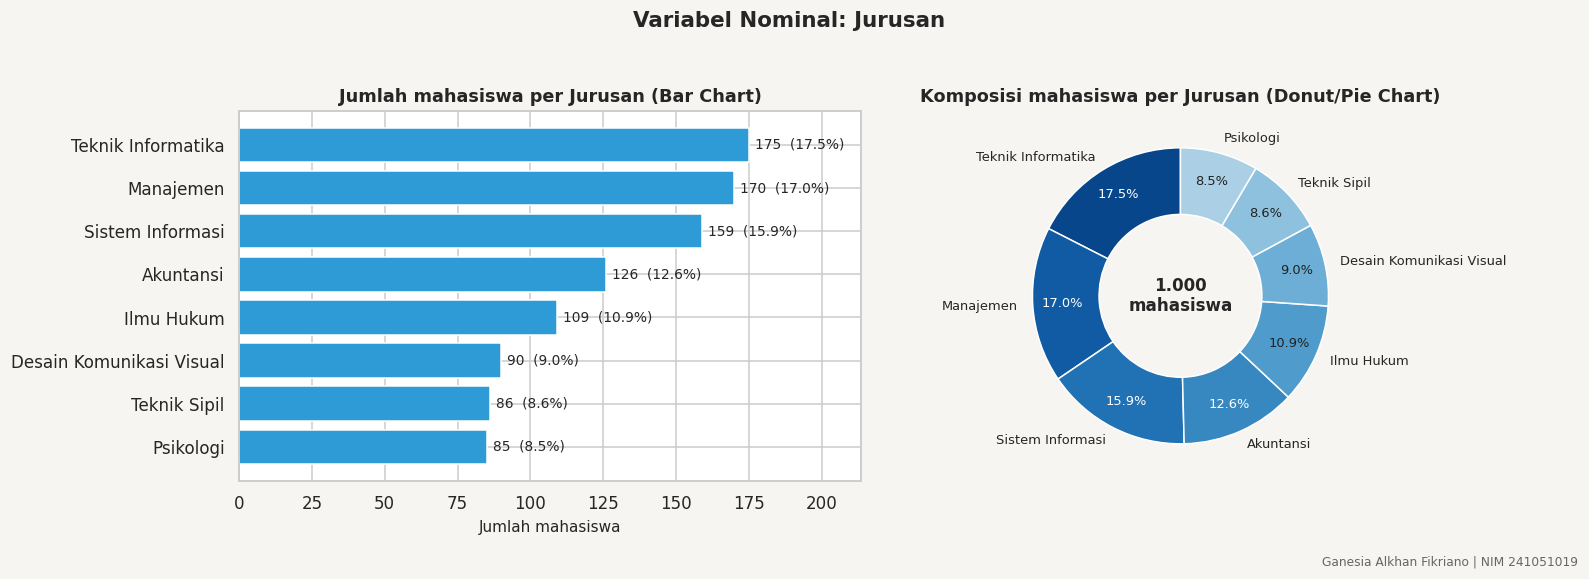

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(14.5, 5.2))

urut = tab_jur.sort_values("Jumlah").index.astype(str)
nilai = tab_jur.loc[urut, "Jumlah"]
bars = ax[0].barh(urut, nilai, color=BIRU, edgecolor="white")
ax[0].bar_label(bars, labels=[f"{v}  ({v/len(df):.1%})" for v in nilai], padding=4, fontsize=9)
ax[0].set_xlim(0, nilai.max() * 1.22)
ax[0].set(title="Jumlah mahasiswa per Jurusan (Bar Chart)", xlabel="Jumlah mahasiswa", ylabel="")

w, t, a = ax[1].pie(tab_jur["Jumlah"], labels=tab_jur.index.astype(str), colors=sns.color_palette("Blues_r", 11)[:8],
                    autopct=lambda p: f"{p:.1f}%", startangle=90, pctdistance=0.8, textprops={"fontsize": 8.5},
                    wedgeprops=dict(width=0.45, edgecolor="white"))
for x, v in zip(a, tab_jur["Persen"]):
    x.set_color("white" if v > 12 else "#222")
ax[1].set_title("Komposisi mahasiswa per Jurusan (Donut/Pie Chart)")
ax[1].text(0, 0, f"{len(df):,}\nmahasiswa".replace(",", "."), ha="center", va="center", fontsize=11, fontweight="bold")
selesai(fig, "Variabel Nominal: Jurusan")

## 6. Semester - Kategorik Ordinal

Semester memiliki **tingkatan dan urutan yang jelas** (1 -> 2 -> 3 ...). Karena itu:
- bar chart harus disusun **berurutan** menurut semester, bukan diurutkan berdasarkan jumlah;
- ukuran pemusatan yang tepat adalah **median dan modus** (bukan rata-rata), ditambah **kuartil** dan **persentase kumulatif**.

In [8]:
tab_sem = df["Semester"].value_counts().reindex(SEM_URUT).to_frame("Jumlah")
tab_sem["Persen"] = tab_sem["Jumlah"] / len(df) * 100
tab_sem["Persen_Kumulatif"] = tab_sem["Persen"].cumsum()
display(tab_sem.style.format({"Persen": "{:.1f}%", "Persen_Kumulatif": "{:.1f}%"}))

s = df["Sem"]
print(f"Modus     : semester {s.mode()[0]}")
print(f"Median    : semester {s.median():.0f}")
print(f"Kuartil   : Q1 = {s.quantile(.25):.0f}, Q3 = {s.quantile(.75):.0f}  (50% mahasiswa berada di semester {s.quantile(.25):.0f} - {s.quantile(.75):.0f})")
print(f"Di masa studi normal (semester 1-8): {(s <= 8).mean():.1%} | memperpanjang studi (9-10): {(s > 8).mean():.1%}")

,Jumlah,Persen,Persen_Kumulatif
Semester,,,
1,186,18.6%,18.6%
2,174,17.4%,36.0%
3,154,15.4%,51.4%
4,114,11.4%,62.8%
5,106,10.6%,73.4%
6,116,11.6%,85.0%
7,85,8.5%,93.5%
8,52,5.2%,98.7%
9,7,0.7%,99.4%


Modus     : semester 1
Median    : semester 3
Kuartil   : Q1 = 2, Q3 = 6  (50% mahasiswa berada di semester 2 - 6)
Di masa studi normal (semester 1-8): 98.7% | memperpanjang studi (9-10): 1.3%


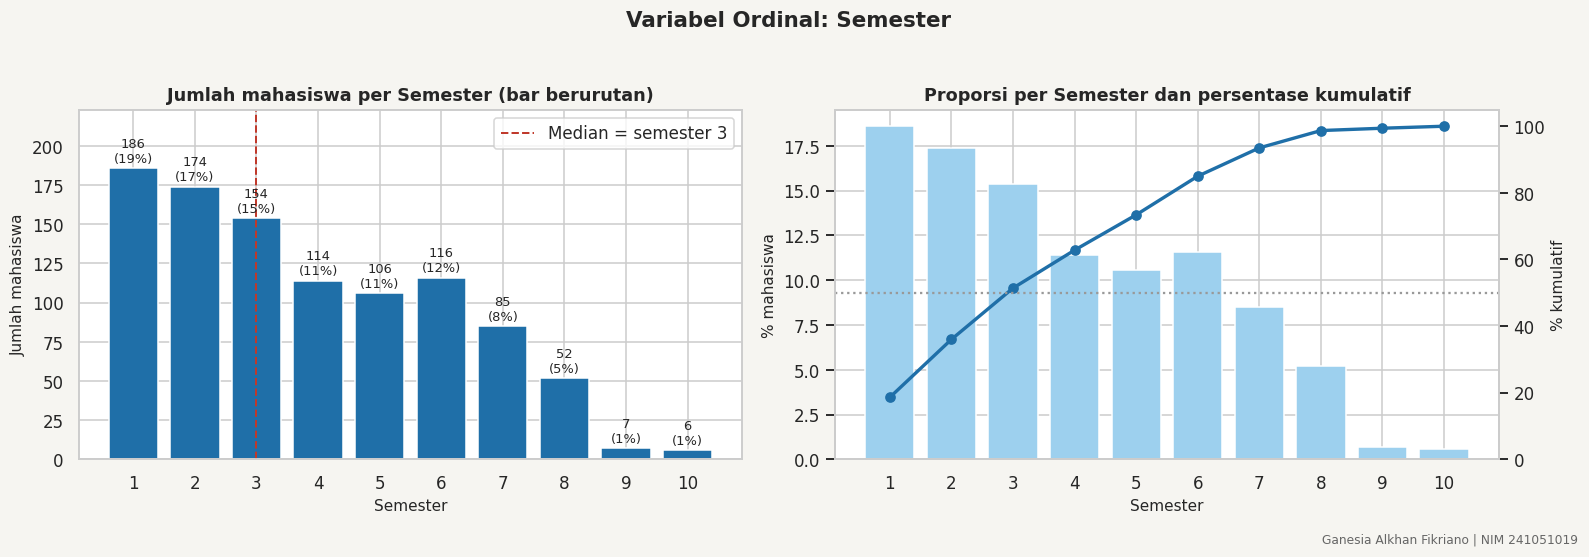

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(14.5, 5))

# (a) Bar chart berurutan
b = ax[0].bar(tab_sem.index.astype(str), tab_sem["Jumlah"], color=BIRU_TUA, edgecolor="white")
ax[0].bar_label(b, labels=[f"{v}\n({p:.0f}%)" for v, p in zip(tab_sem["Jumlah"], tab_sem["Persen"])], fontsize=8.5, padding=2)
ax[0].axvline(list(SEM_URUT).index(int(s.median())), color="#C0392B", ls="--", lw=1.3, label=f"Median = semester {s.median():.0f}")
ax[0].set_ylim(0, tab_sem["Jumlah"].max() * 1.2)
ax[0].set(title="Jumlah mahasiswa per Semester (bar berurutan)", xlabel="Semester", ylabel="Jumlah mahasiswa")
ax[0].legend()

# (b) Persentase kumulatif
ax[1].bar(tab_sem.index.astype(str), tab_sem["Persen"], color="#9DD0EE", edgecolor="white", label="% per semester")
ax2 = ax[1].twinx()
ax2.plot(tab_sem.index.astype(str), tab_sem["Persen_Kumulatif"], color=BIRU_TUA, marker="o", lw=2.2, label="% kumulatif")
ax2.axhline(50, color="#999", ls=":"); ax2.set_ylim(0, 105); ax2.grid(False)
ax2.set_ylabel("% kumulatif")
ax[1].set(title="Proporsi per Semester dan persentase kumulatif", xlabel="Semester", ylabel="% mahasiswa")
selesai(fig, "Variabel Ordinal: Semester")

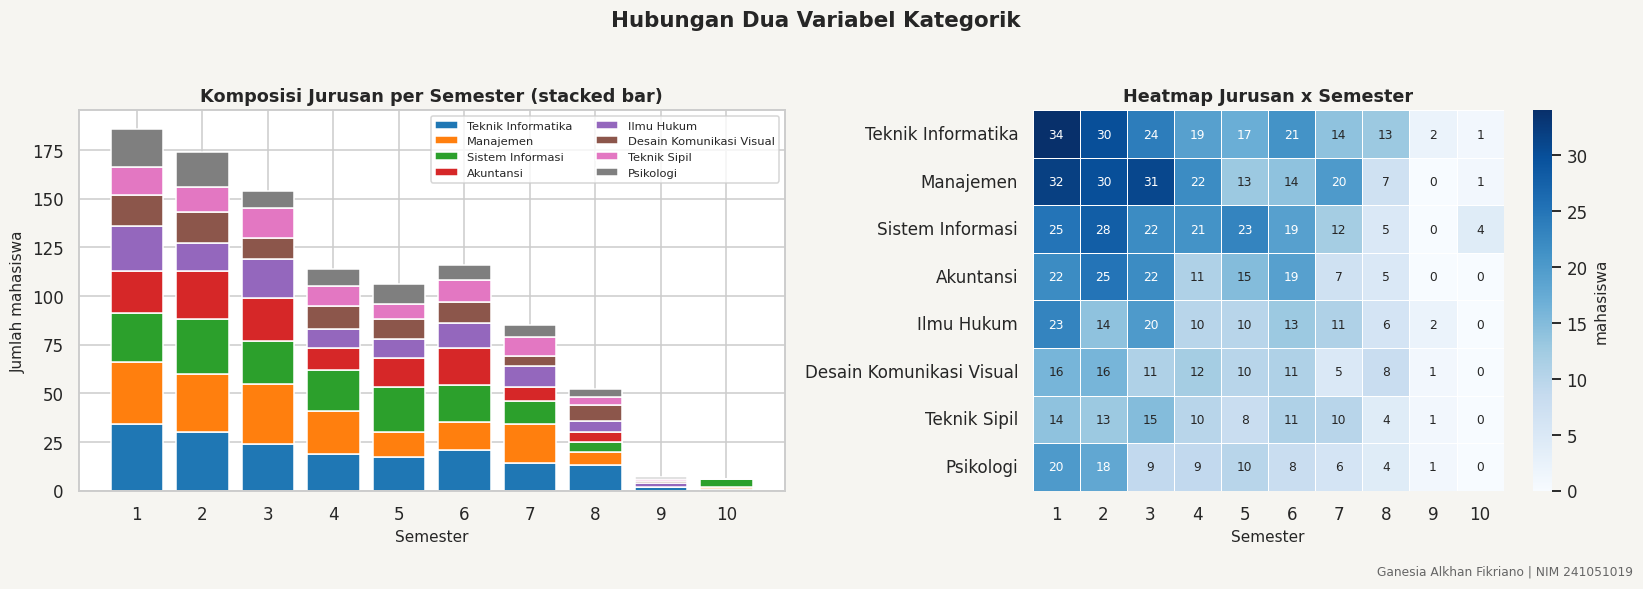

Uji chi-square Jurusan vs Semester (semester 8-10 digabung): chi2 = 32.4, dof = 49, p = 0.967 -> tidak ada bukti hubungan; sebaran semester relatif sama di semua jurusan


In [10]:
# Komposisi Jurusan di setiap Semester (tetap berurutan menurut semester)
ct = pd.crosstab(df["Semester"], df["Jurusan"]).reindex(SEM_URUT)
urut_kolom = tab_jur.index.tolist()
fig, ax = plt.subplots(1, 2, figsize=(15, 5.3), gridspec_kw={"width_ratios": [1.2, 1]})
bottom = np.zeros(len(ct))
for i, j in enumerate(urut_kolom):
    ax[0].bar(ct.index.astype(str), ct[j], bottom=bottom, color=PALET_JUR[i], edgecolor="white", label=str(j))
    bottom += ct[j].values
ax[0].set(title="Komposisi Jurusan per Semester (stacked bar)", xlabel="Semester", ylabel="Jumlah mahasiswa")
ax[0].legend(fontsize=7.5, ncol=2, loc="upper right")

sns.heatmap(ct.T.loc[urut_kolom], annot=True, fmt="d", cmap="Blues", linewidths=.5, cbar_kws={"label": "mahasiswa"}, ax=ax[1], annot_kws={"fontsize": 8})
ax[1].set(title="Heatmap Jurusan x Semester", xlabel="Semester", ylabel="")
selesai(fig, "Hubungan Dua Variabel Kategorik")

chi2, p, dof, _ = stats.chi2_contingency(pd.crosstab(df["Jurusan"], df["Sem"].clip(upper=8)))
hasil = "ada bukti hubungan Jurusan dan Semester" if p < .05 else "tidak ada bukti hubungan; sebaran semester relatif sama di semua jurusan"
print(f"Uji chi-square Jurusan vs Semester (semester 8-10 digabung): chi2 = {chi2:.1f}, dof = {dof}, p = {p:.3f} -> {hasil}")

## 7. IPK - Numerik Kontinu

IPK berskala **kontinu** (0,00-4,00), sehingga seluruh statistik deskriptif bermakna. Sesuai gambar, visualisasi yang cocok adalah **histogram** (bentuk distribusi) dan **box plot** (sebaran dan pencilan). Karena IPK dibatasi maksimum 4,00, distribusinya biasanya **miring ke kiri** (ekor panjang di IPK rendah).

In [11]:
ipk = df["IPK"]
desk = ipk.describe(percentiles=[.05, .25, .5, .75, .95]).to_frame("IPK")
desk.loc["skewness"] = stats.skew(ipk)
desk.loc["kurtosis (excess)"] = stats.kurtosis(ipk)
desk.loc["koef. variasi (%)"] = ipk.std() / ipk.mean() * 100
desk.loc["modus"] = ipk.mode()[0]
display(desk.style.format("{:.3f}"))

q1, q3 = ipk.quantile([.25, .75]); iqr = q3 - q1
bawah, atas = q1 - 1.5 * iqr, q3 + 1.5 * iqr
out = df[(ipk < bawah) | (ipk > atas)]
print(f"IQR = {iqr:.2f} | pagar bawah = {bawah:.2f} | pagar atas = {atas:.2f}")
print(f"Pencilan: {len(out)} mahasiswa ({len(out)/len(df):.1%}); seluruhnya di sisi {'bawah (IPK rendah)' if (out['IPK'] < bawah).all() else 'campuran'}")

stat_n, p_n = stats.normaltest(ipk)
stat_s, p_s = stats.shapiro(ipk)
print(f"Uji kenormalan: D'Agostino p = {p_n:.2e} | Shapiro-Wilk p = {p_s:.2e} -> "
      f"{'tolak' if min(p_n, p_s) < .05 else 'tidak menolak'} H0 (distribusi normal)")

,IPK
count,1000.000
mean,3.273
std,0.363
min,1.330
5%,2.629
25%,3.050
50%,3.290
75%,3.520
95%,3.840
max,3.970


IQR = 0.47 | pagar bawah = 2.34 | pagar atas = 4.23
Pencilan: 14 mahasiswa (1.4%); seluruhnya di sisi bawah (IPK rendah)
Uji kenormalan: D'Agostino p = 2.79e-19 | Shapiro-Wilk p = 6.64e-12 -> tolak H0 (distribusi normal)


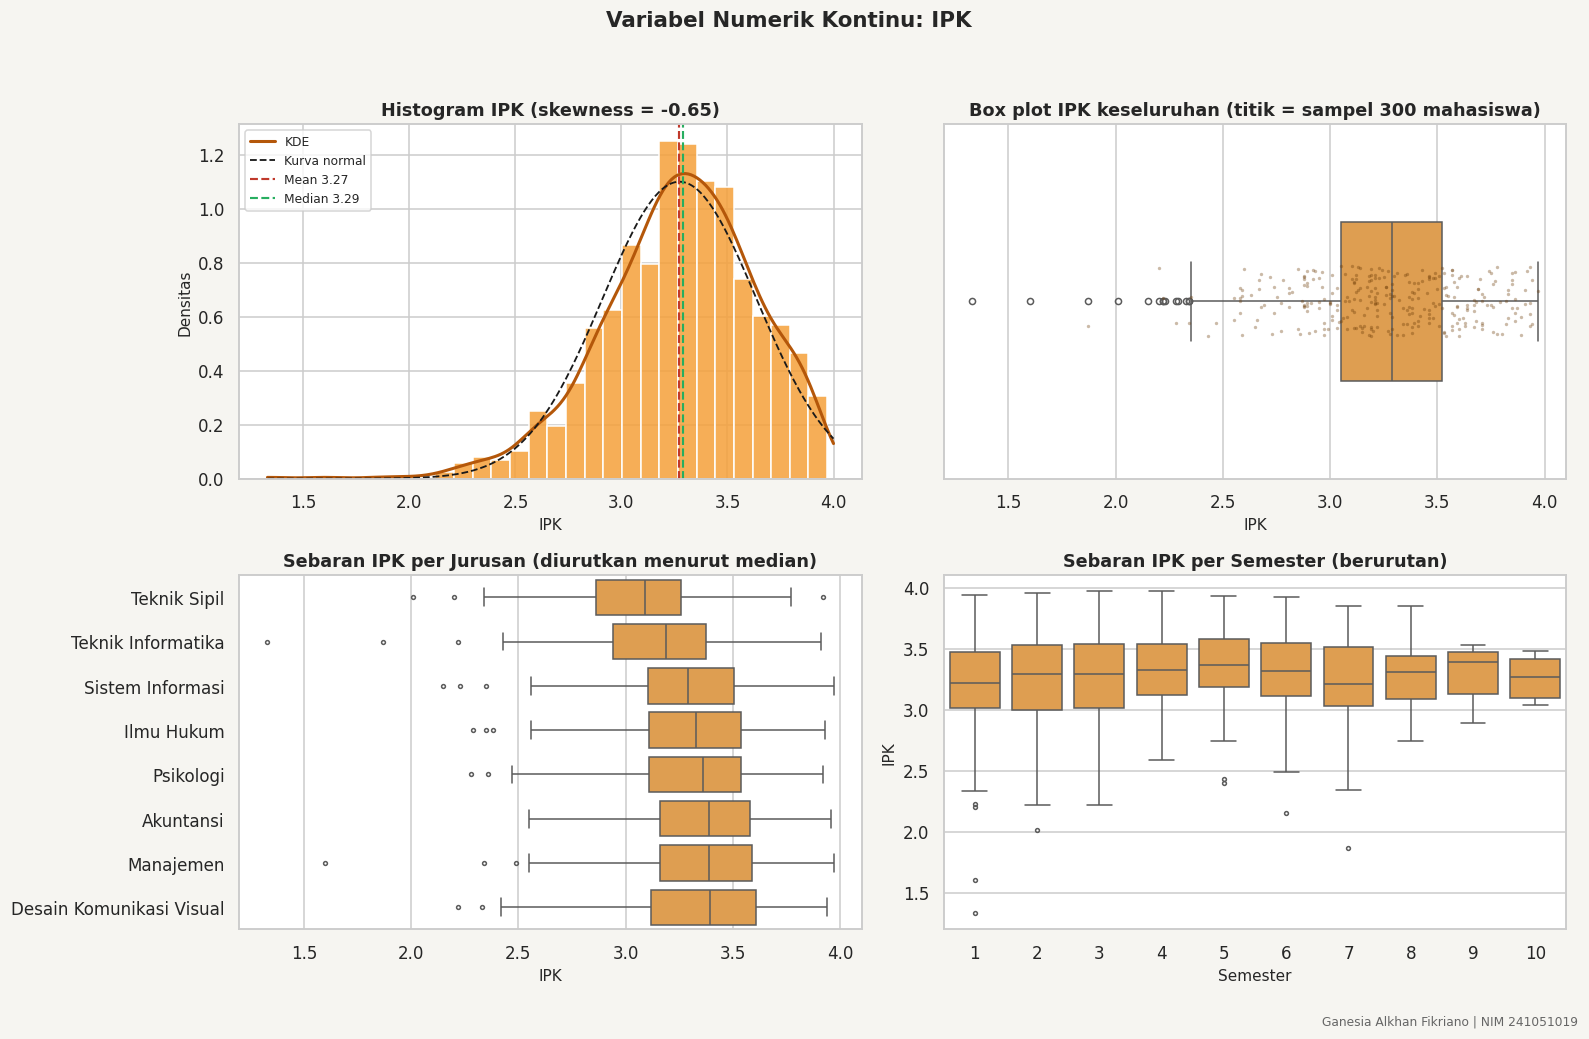

In [12]:
fig, ax = plt.subplots(2, 2, figsize=(14.5, 9.5))

# (a) Histogram + KDE + kurva normal
sns.histplot(ipk, bins=30, stat="density", color=ORANYE, edgecolor="white", alpha=.85, ax=ax[0, 0])
sns.kdeplot(ipk, color="#B4570A", lw=2, clip=(ipk.min(), 4.0), ax=ax[0, 0], label="KDE")
xs = np.linspace(ipk.min(), 4.0, 300)
ax[0, 0].plot(xs, stats.norm.pdf(xs, ipk.mean(), ipk.std()), "k--", lw=1.2, label="Kurva normal")
ax[0, 0].axvline(ipk.mean(), color="#C0392B", ls="--", lw=1.4, label=f"Mean {ipk.mean():.2f}")
ax[0, 0].axvline(ipk.median(), color="#27AE60", ls="--", lw=1.4, label=f"Median {ipk.median():.2f}")
ax[0, 0].set(title=f"Histogram IPK (skewness = {stats.skew(ipk):.2f})", xlabel="IPK", ylabel="Densitas")
ax[0, 0].legend(fontsize=8)

# (b) Box plot keseluruhan + sebaran titik
sns.boxplot(x=ipk, color=ORANYE, fliersize=4, width=.45, ax=ax[0, 1])
sns.stripplot(x=ipk.sample(300, random_state=1), color="#6b3a05", size=2.2, alpha=.35, ax=ax[0, 1])
ax[0, 1].set(title="Box plot IPK keseluruhan (titik = sampel 300 mahasiswa)", xlabel="IPK")

# (c) Box plot per Jurusan
urut_j = df.groupby("Jurusan", observed=True)["IPK"].median().sort_values().index.astype(str)
sns.boxplot(data=df.assign(Jurusan=df["Jurusan"].astype(str)), y="Jurusan", x="IPK", order=urut_j, color=ORANYE, fliersize=2.5, linewidth=1, ax=ax[1, 0])
ax[1, 0].set(title="Sebaran IPK per Jurusan (diurutkan menurut median)", ylabel="", xlabel="IPK")

# (d) Box plot per Semester (berurutan)
sns.boxplot(data=df.assign(Semester=df["Sem"].astype(str)), x="Semester", y="IPK", order=[str(i) for i in SEM_URUT], color=ORANYE, fliersize=2.5, linewidth=1, ax=ax[1, 1])
ax[1, 1].set(title="Sebaran IPK per Semester (berurutan)", xlabel="Semester", ylabel="IPK")
selesai(fig, "Variabel Numerik Kontinu: IPK")

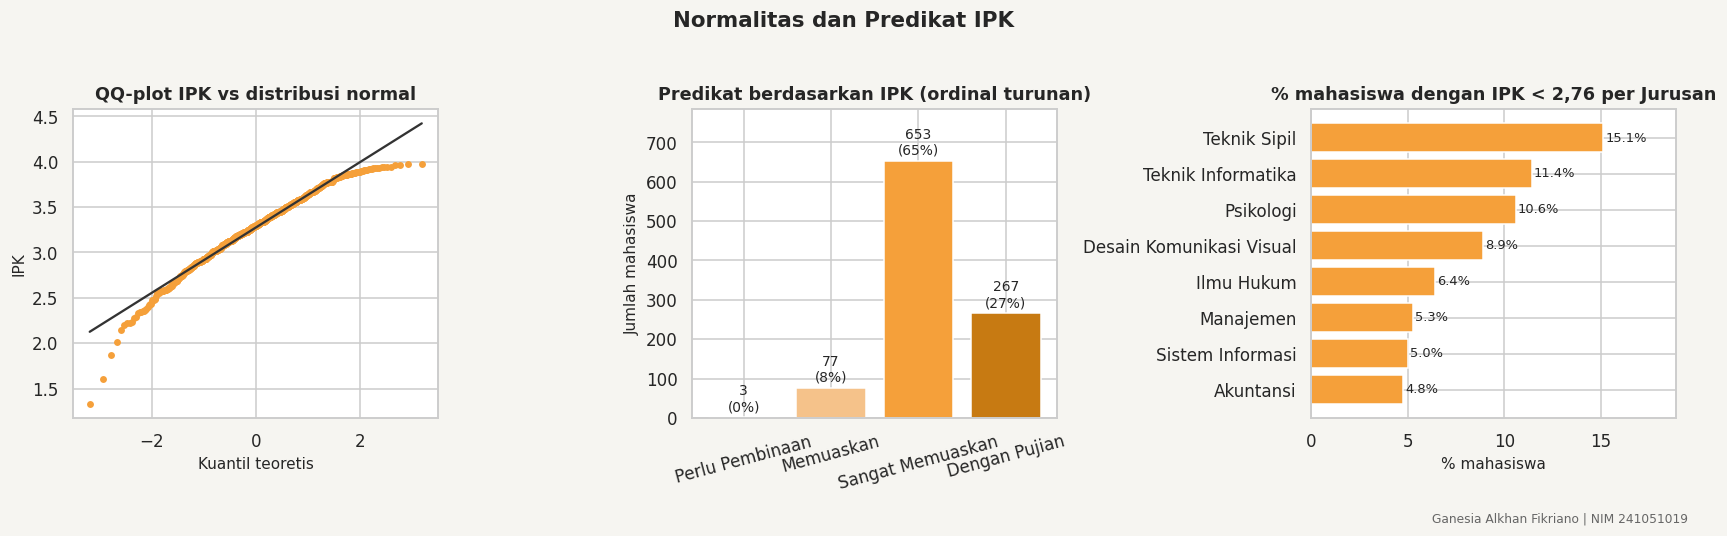

,Jumlah,Persen
Predikat,,
Perlu Pembinaan,3,0.3%
Memuaskan,77,7.7%
Sangat Memuaskan,653,65.3%
Dengan Pujian,267,26.7%


In [13]:
# Normalitas visual (QQ-plot) dan predikat kelulusan
fig, ax = plt.subplots(1, 3, figsize=(15.5, 4.8))
stats.probplot(ipk, dist="norm", plot=ax[0])
ax[0].get_lines()[0].set(color=ORANYE, markersize=3.5); ax[0].get_lines()[1].set(color="#333")
ax[0].set(title="QQ-plot IPK vs distribusi normal", xlabel="Kuantil teoretis", ylabel="IPK")

pred = df["Predikat"].value_counts().reindex(PREDIKAT)
b = ax[1].bar(PREDIKAT, pred.values, color=[ "#E8A87C", "#F5C28A", ORANYE, "#C77A12"], edgecolor="white")
ax[1].bar_label(b, labels=[f"{v}\n({v/len(df):.0%})" for v in pred.values], fontsize=9, padding=2)
ax[1].set_ylim(0, pred.max() * 1.2)
ax[1].set(title="Predikat berdasarkan IPK (ordinal turunan)", ylabel="Jumlah mahasiswa")
ax[1].tick_params(axis="x", labelrotation=15)

risiko = df.assign(Risiko=df["IPK"] < 2.76).groupby("Jurusan", observed=True)["Risiko"].mean().sort_values() * 100
ax[2].barh(risiko.index.astype(str), risiko.values, color=ORANYE, edgecolor="white")
for i, v in enumerate(risiko.values):
    ax[2].text(v + .1, i, f"{v:.1f}%", va="center", fontsize=8.5)
ax[2].set_xlim(0, risiko.max() * 1.25)
ax[2].set(title="% mahasiswa dengan IPK < 2,76 per Jurusan", xlabel="% mahasiswa")
selesai(fig, "Normalitas dan Predikat IPK")
display(pd.DataFrame({"Jumlah": pred, "Persen": pred / len(df) * 100}).style.format({"Persen": "{:.1f}%"}))

## 8. Usia - Numerik Kontinu

Usia adalah pengukuran kontinu yang dicatat dalam tahun penuh. Visualisasi: **histogram** (lebar kelas 1 tahun) dan **box plot**. Distribusi usia mahasiswa lazimnya **miring ke kanan** karena ada sebagian kecil mahasiswa dewasa.

In [14]:
usia = df["Usia"]
desk_u = usia.describe(percentiles=[.05, .25, .5, .75, .95]).to_frame("Usia")
desk_u.loc["skewness"] = stats.skew(usia)
desk_u.loc["kurtosis (excess)"] = stats.kurtosis(usia)
desk_u.loc["modus"] = usia.mode()[0]
display(desk_u.style.format("{:.2f}"))

q1u, q3u = usia.quantile([.25, .75]); iqru = q3u - q1u
atas_u = q3u + 1.5 * iqru
dewasa = df[usia > atas_u]
print(f"IQR = {iqru:.0f} tahun | pagar atas = {atas_u:.1f} tahun | pencilan = {len(dewasa)} mahasiswa ({len(dewasa)/len(df):.1%}), usia {dewasa['Usia'].min()}-{dewasa['Usia'].max()} tahun")
print("Catatan: pencilan usia adalah mahasiswa dewasa/pekerja yang valid, bukan kesalahan data.")
display(df["Kelompok_Usia"].value_counts().sort_index().to_frame("Jumlah").assign(Persen=lambda d: d["Jumlah"] / len(df) * 100).style.format({"Persen": "{:.1f}%"}))

,Usia
count,1000.00
mean,19.68
std,2.02
min,17.00
5%,18.00
25%,18.00
50%,19.00
75%,20.00
95%,22.00
max,34.00


IQR = 2 tahun | pagar atas = 23.0 tahun | pencilan = 33 mahasiswa (3.3%), usia 24-34 tahun
Catatan: pencilan usia adalah mahasiswa dewasa/pekerja yang valid, bukan kesalahan data.


,Jumlah,Persen
Kelompok_Usia,,
<= 18,276,27.6%
19,266,26.6%
20,227,22.7%
21,133,13.3%
22,52,5.2%
>= 23,46,4.6%


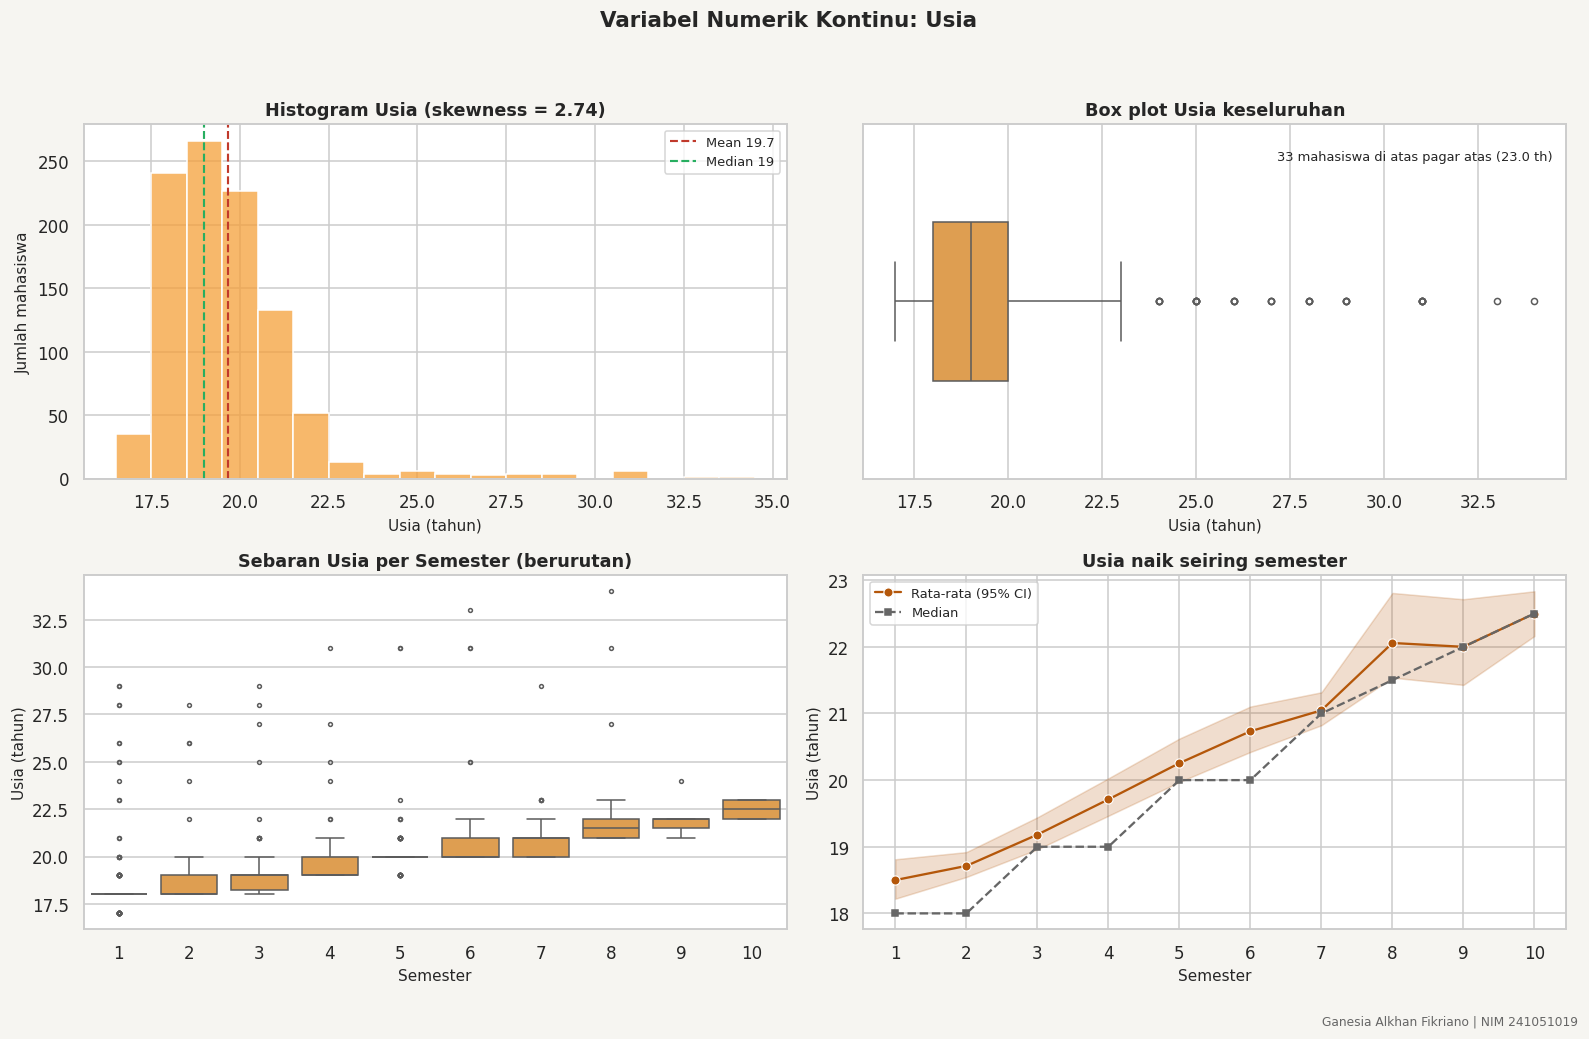

In [15]:
fig, ax = plt.subplots(2, 2, figsize=(14.5, 9.5))

# (a) Histogram usia (lebar kelas 1 tahun)
sns.histplot(usia, binwidth=1, binrange=(16.5, usia.max() + .5), color=ORANYE, edgecolor="white", ax=ax[0, 0])
ax[0, 0].axvline(usia.mean(), color="#C0392B", ls="--", lw=1.4, label=f"Mean {usia.mean():.1f}")
ax[0, 0].axvline(usia.median(), color="#27AE60", ls="--", lw=1.4, label=f"Median {usia.median():.0f}")
ax[0, 0].set(title=f"Histogram Usia (skewness = {stats.skew(usia):.2f})", xlabel="Usia (tahun)", ylabel="Jumlah mahasiswa")
ax[0, 0].legend(fontsize=8.5)

# (b) Box plot keseluruhan
sns.boxplot(x=usia, color=ORANYE, fliersize=4, width=.45, ax=ax[0, 1])
ax[0, 1].text(0.98, 0.9, f"{len(dewasa)} mahasiswa di atas pagar atas ({atas_u:.1f} th)", transform=ax[0, 1].transAxes, ha="right", fontsize=8.5)
ax[0, 1].set(title="Box plot Usia keseluruhan", xlabel="Usia (tahun)")

# (c) Box plot per semester
sns.boxplot(data=df.assign(Semester=df["Sem"].astype(str)), x="Semester", y="Usia", order=[str(i) for i in SEM_URUT], color=ORANYE, fliersize=2.5, linewidth=1, ax=ax[1, 0])
ax[1, 0].set(title="Sebaran Usia per Semester (berurutan)", xlabel="Semester", ylabel="Usia (tahun)")

# (d) Usia rata-rata per semester (95% CI) + median
sns.lineplot(data=df, x="Sem", y="Usia", errorbar=("ci", 95), marker="o", color="#B4570A", ax=ax[1, 1], label="Rata-rata (95% CI)")
med_u = df.groupby("Sem")["Usia"].median()
ax[1, 1].plot(med_u.index, med_u.values, "s--", color="#666", ms=4, label="Median")
ax[1, 1].set_xticks(SEM_URUT)
ax[1, 1].set(title="Usia naik seiring semester", xlabel="Semester", ylabel="Usia (tahun)")
ax[1, 1].legend(fontsize=8.5)
selesai(fig, "Variabel Numerik Kontinu: Usia")

## 9. Hubungan Antar Variabel

Karena IPK miring ke kiri dan Semester berskala ordinal, korelasi **Spearman** (berbasis peringkat) dipakai sebagai ukuran utama, dengan Pearson sebagai pembanding untuk dua variabel kontinu. Perbedaan antar jurusan diuji dengan **Kruskal-Wallis**.

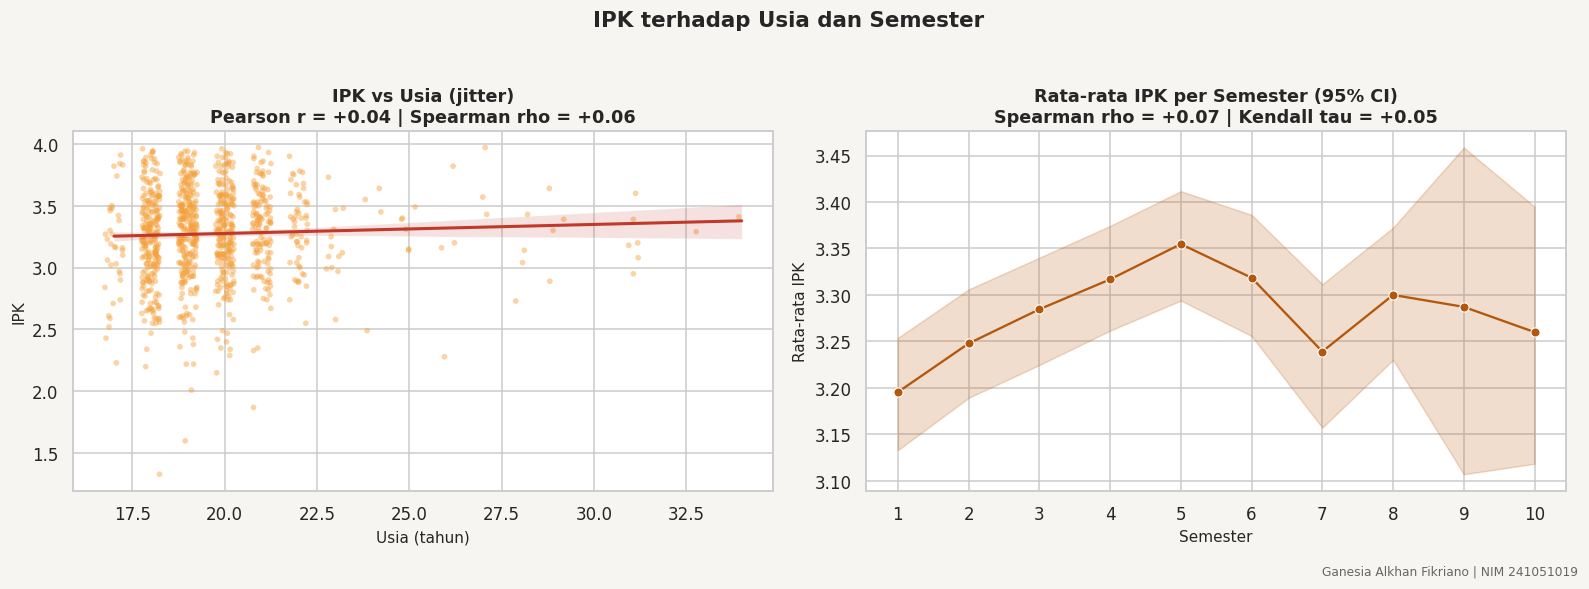

IPK vs Usia    : Pearson r = +0.041 (p = 0.200), Spearman rho = +0.061 (p = 0.054)
IPK vs Semester: Spearman rho = +0.073 (p = 0.021), Kendall tau = +0.051 (p = 0.023)


In [16]:
r_p, p_p = stats.pearsonr(df["IPK"], df["Usia"])
r_s, p_s2 = stats.spearmanr(df["IPK"], df["Usia"])
r_sem, p_sem = stats.spearmanr(df["IPK"], df["Sem"])
tau, p_tau = stats.kendalltau(df["IPK"], df["Sem"])

fig, ax = plt.subplots(1, 2, figsize=(14.5, 5.3))
rng = np.random.default_rng(1)
jx = df["Usia"] + rng.uniform(-.25, .25, len(df))          # jitter agar titik usia bulat tidak menumpuk
ax[0].scatter(jx, df["IPK"], s=14, alpha=.45, color=ORANYE, edgecolor="none")
sns.regplot(data=df, x="Usia", y="IPK", scatter=False, color="#C0392B", line_kws={"lw": 2}, ci=95, ax=ax[0])
ax[0].set(title=f"IPK vs Usia (jitter)\nPearson r = {r_p:+.2f} | Spearman rho = {r_s:+.2f}", xlabel="Usia (tahun)", ylabel="IPK")

sns.lineplot(data=df, x="Sem", y="IPK", errorbar=("ci", 95), marker="o", color="#B4570A", ax=ax[1])
ax[1].set_xticks(SEM_URUT)
ax[1].set(title=f"Rata-rata IPK per Semester (95% CI)\nSpearman rho = {r_sem:+.2f} | Kendall tau = {tau:+.2f}", xlabel="Semester", ylabel="Rata-rata IPK")
selesai(fig, "IPK terhadap Usia dan Semester")

print(f"IPK vs Usia    : Pearson r = {r_p:+.3f} (p = {p_p:.3f}), Spearman rho = {r_s:+.3f} (p = {p_s2:.3f})")
print(f"IPK vs Semester: Spearman rho = {r_sem:+.3f} (p = {p_sem:.3f}), Kendall tau = {tau:+.3f} (p = {p_tau:.3f})")

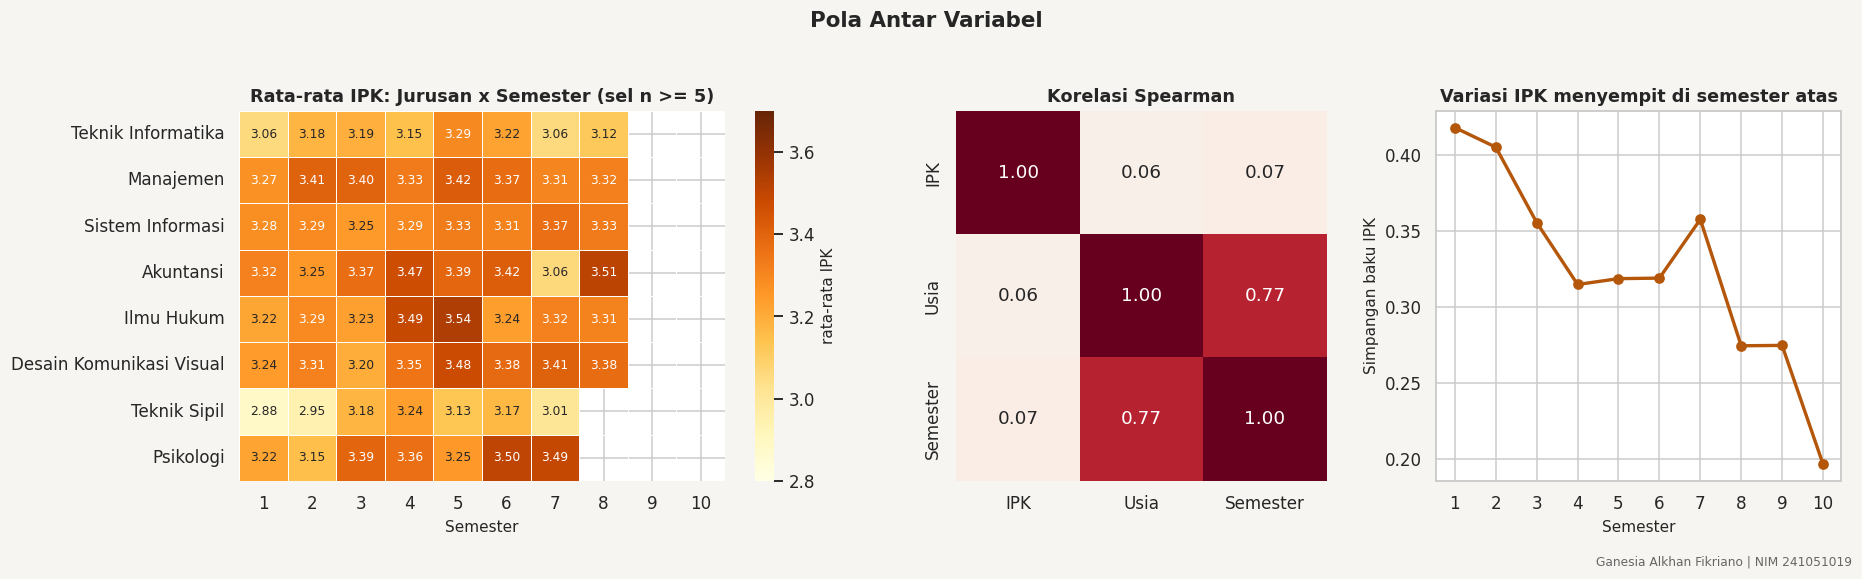

In [17]:
fig, ax = plt.subplots(1, 3, figsize=(17, 5.2), gridspec_kw={"width_ratios": [1.5, 1, 1]})

# Rata-rata IPK Jurusan x Semester (hanya sel dengan n >= 5)
pv = df.pivot_table(index="Jurusan", columns="Sem", values="IPK", aggfunc="mean", observed=True)
n_sel = df.pivot_table(index="Jurusan", columns="Sem", values="IPK", aggfunc="count", observed=True)
pv = pv.where(n_sel >= 5).loc[tab_jur.index]
sns.heatmap(pv, annot=True, fmt=".2f", cmap="YlOrBr", vmin=2.8, vmax=3.7, linewidths=.5, cbar_kws={"label": "rata-rata IPK"}, ax=ax[0], annot_kws={"fontsize": 8})
ax[0].set(title="Rata-rata IPK: Jurusan x Semester (sel n >= 5)", xlabel="Semester", ylabel="")

# Matriks korelasi Spearman
cor = df[["IPK", "Usia", "Sem"]].rename(columns={"Sem": "Semester"}).corr(method="spearman")
sns.heatmap(cor, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, square=True, ax=ax[1], cbar=False)
ax[1].set_title("Korelasi Spearman")

# Simpangan baku IPK per semester (kumulatif -> menyempit)
sd_sem = df.groupby("Sem")["IPK"].std()
ax[2].plot(sd_sem.index, sd_sem.values, marker="o", color="#B4570A", lw=2.2)
ax[2].set_xticks(SEM_URUT)
ax[2].set(title="Variasi IPK menyempit di semester atas", xlabel="Semester", ylabel="Simpangan baku IPK")
selesai(fig, "Pola Antar Variabel")

In [18]:
n = len(df)
uji = []
for var, grp, nm in [("IPK", "Jurusan", "IPK ~ Jurusan"), ("IPK", "Sem", "IPK ~ Semester"), ("Usia", "Jurusan", "Usia ~ Jurusan"), ("Usia", "Sem", "Usia ~ Semester")]:
    H, p = stats.kruskal(*[g[var].values for _, g in df.groupby(grp, observed=True)])
    uji.append({"Uji": nm, "H": H, "p-value": p, "Epsilon^2": H / (n - 1),
                "Kesimpulan": "berbeda signifikan" if p < .05 else "tidak berbeda signifikan"})
uji = pd.DataFrame(uji)
display(uji.style.format({"H": "{:.1f}", "p-value": "{:.2e}", "Epsilon^2": "{:.3f}"}))
print("Epsilon^2 (ukuran efek): ~0.01 kecil, ~0.06 sedang, >= 0.14 besar.")

,Uji,H,p-value,Epsilon^2,Kesimpulan
0,IPK ~ Jurusan,69.7,1.67e-12,0.070,berbeda signifikan
1,IPK ~ Semester,15.6,7.65e-02,0.016,tidak berbeda signifikan
2,Usia ~ Jurusan,6.8,4.49e-01,0.007,tidak berbeda signifikan
3,Usia ~ Semester,600.8,1.42e-123,0.601,berbeda signifikan


Epsilon^2 (ukuran efek): ~0.01 kecil, ~0.06 sedang, >= 0.14 besar.


## 10. Temuan Utama & Kesimpulan

In [19]:
top_j = tab_jur.index[0]
j_ipk_tinggi = df.groupby("Jurusan", observed=True)["IPK"].mean().idxmax()
j_ipk_rendah = df.groupby("Jurusan", observed=True)["IPK"].mean().idxmin()
m_j = df.groupby("Jurusan", observed=True)["IPK"].mean()
pct_pujian = (df["IPK"] >= 3.51).mean(); pct_bina = (df["IPK"] < 2.0).mean(); pct_risk = (df["IPK"] < 2.76).mean()

temuan = f"""
**Jurusan (nominal)**
- Jurusan terbesar: **{top_j}** ({tab_jur.loc[top_j, 'Persen']:.1f}%); tiga jurusan terbesar mencakup {tab_jur['Persen'].head(3).sum():.1f}% mahasiswa.
- Rata-rata IPK tertinggi: **{j_ipk_tinggi}** ({m_j.max():.2f}); terendah: **{j_ipk_rendah}** ({m_j.min():.2f}). Selisih antar jurusan {'signifikan' if uji.loc[0, 'p-value'] < .05 else 'tidak signifikan'} (Kruskal-Wallis p = {uji.loc[0, 'p-value']:.1e}, ukuran efek {uji.loc[0, 'Epsilon^2']:.3f}).

**Semester (ordinal)**
- Median semester = **{s.median():.0f}**, modus = **{s.mode()[0]}**. {(s <= 4).mean():.0%} mahasiswa berada di semester 1-4; hanya {(s > 8).mean():.1%} yang memperpanjang studi (semester 9-10).

**IPK (kontinu)**
- Rata-rata {ipk.mean():.2f}, median {ipk.median():.2f}, simpangan baku {ipk.std():.2f}. Skewness = {stats.skew(ipk):.2f} (miring ke kiri), dan uji kenormalan {'menolak' if min(p_n, p_s) < .05 else 'tidak menolak'} H0 normal.
- {pct_pujian:.0%} mahasiswa berpredikat *Dengan Pujian* (IPK >= 3,51); {pct_risk:.0%} berada di bawah 2,76; {pct_bina:.1%} di bawah 2,00 (perlu pembinaan).
- Ada {len(out)} pencilan IPK rendah ({len(out)/n:.1%}).

**Usia (kontinu)**
- Rata-rata {usia.mean():.1f} tahun, median {usia.median():.0f}, rentang {usia.min()}-{usia.max()} tahun; miring ke kanan (skewness = {stats.skew(usia):.2f}) karena ada {len(dewasa)} mahasiswa dewasa.

**Hubungan**
- Usia sangat berkorelasi dengan semester (rho = {cor.loc['Usia', 'Semester']:.2f}), sedangkan IPK vs Usia hampir tidak berkorelasi (rho = {r_s:+.2f}) dan IPK vs Semester lemah (rho = {r_sem:+.2f}).
- Variasi IPK mengecil dari simpangan baku {sd_sem.loc[1]:.2f} (semester 1) menjadi {sd_sem.loc[8]:.2f} (semester 8), sesuai sifat IPK yang kumulatif.
"""
display(Markdown(temuan))


**Jurusan (nominal)**
- Jurusan terbesar: **Teknik Informatika** (17.5%); tiga jurusan terbesar mencakup 50.4% mahasiswa.
- Rata-rata IPK tertinggi: **Manajemen** (3.35); terendah: **Teknik Sipil** (3.07). Selisih antar jurusan signifikan (Kruskal-Wallis p = 1.7e-12, ukuran efek 0.070).

**Semester (ordinal)**
- Median semester = **3**, modus = **1**. 63% mahasiswa berada di semester 1-4; hanya 1.3% yang memperpanjang studi (semester 9-10).

**IPK (kontinu)**
- Rata-rata 3.27, median 3.29, simpangan baku 0.36. Skewness = -0.65 (miring ke kiri), dan uji kenormalan menolak H0 normal.
- 27% mahasiswa berpredikat *Dengan Pujian* (IPK >= 3,51); 8% berada di bawah 2,76; 0.3% di bawah 2,00 (perlu pembinaan).
- Ada 14 pencilan IPK rendah (1.4%).

**Usia (kontinu)**
- Rata-rata 19.7 tahun, median 19, rentang 17-34 tahun; miring ke kanan (skewness = 2.74) karena ada 33 mahasiswa dewasa.

**Hubungan**
- Usia sangat berkorelasi dengan semester (rho = 0.77), sedangkan IPK vs Usia hampir tidak berkorelasi (rho = +0.06) dan IPK vs Semester lemah (rho = +0.07).
- Variasi IPK mengecil dari simpangan baku 0.42 (semester 1) menjadi 0.27 (semester 8), sesuai sifat IPK yang kumulatif.


**Kesimpulan.** Data sintetis 1.000 baris berhasil meniru struktur dan tipe data pada gambar tugas. Analisis menunjukkan bahwa **pemilihan statistik dan visualisasi harus mengikuti skala pengukuran**:
- **Nominal (Jurusan):** bar chart terurut dan donut/pie, dengan frekuensi dan modus.
- **Ordinal (Semester):** bar chart yang **mempertahankan urutan**, dengan median, kuartil, dan persentase kumulatif.
- **Kontinu (IPK, Usia):** histogram dan box plot, dengan mean, median, simpangan baku, skewness, dan deteksi pencilan.

IPK yang dibatasi maksimum 4,00 miring ke kiri sehingga median dan korelasi peringkat lebih layak dipakai daripada mean dan korelasi Pearson saja.

## 11. Menjalankan Dashboard Streamlit

File yang disertakan: `app_kasus2.py` dan `data_profil_mahasiswa.csv` (satu folder). `requirements.txt` yang sama dengan Kasus 1 dapat dipakai.

```bash
pip install -r requirements.txt
streamlit run app_kasus2.py
```

Dashboard memuat identitas **Ganesia Alkhan Fikriano - NIM 241051019** pada header, sidebar, dan footer.

---
<div style="text-align:right; color:#666">Ganesia Alkhan Fikriano &nbsp;|&nbsp; NIM 241051019</div>